# Teste A/B - Índice de Desenvolvimento Humano

# Objetivos

Este projeto tem como objetivo explorar a aplicação de testes de hipóteses na comparação do IDHM Educação entre regiões. Para isso, busca:

- Compreender como formular hipóteses e calcular as estatísticas de teste e os valores-p.
- Aprender a escolher o teste estatístico mais adequado à pergunta e às características dos dados.
- Interpretar os resultados considerando o nível de significância e o contexto do problema.


In [1]:
# Imports
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import sqrt
from scipy import stats
from matplotlib.lines import Line2D

# adiciona diretório raiz do projeto ao sys.path
sys.path.insert(0, str(Path.cwd().parent))

# configurações gerais
pd.set_option('display.max_rows', None)
sns.set_theme(style='whitegrid', palette='pastel')
%matplotlib inline

# 1. Testes de Hipóteses

### **Por que usamos testes de hipóteses?**

Em geral, usamos uma amostra para estudar características de uma população. Uma diferença observada entre grupos pode refletir uma diferença real ou surgir pela **variabilidade natural da amostragem**.

O teste de hipóteses oferece um procedimento para avaliar se os dados observados são compatíveis com uma hipótese inicial. Ele ajuda a tomar decisões com base em evidências, mas não prova que uma hipótese é verdadeira nem, por si só, demonstra uma relação de causa e efeito.

### **Etapas de um teste de hipóteses**

#### 1. Formular as hipóteses

Definimos duas hipóteses sobre a população:

- **Hipótese nula (H0):** representa a ausência de diferença ou efeito.
- **Hipótese alternativa (H1):** representa a diferença ou o efeito que queremos investigar.


#### 2. Definir o nível de significância

Antes de realizar o teste, definimos o nível de significância, chamado **alpha**. Ele é o limite usado para decidir se há evidência estatística suficiente contra H0.

Um valor comum é `alpha = 0.05`, mas essa escolha deve ser feita antes de analisar o resultado do teste.

### 3. Escolher e aplicar o teste estatístico

Escolhemos o teste adequado à pergunta, aos dados e aos pressupostos da análise. Em seguida, calculamos a estatística do teste e o **valor-p**.

O valor-p indica quão compatíveis os dados observados — ou resultados mais extremos — seriam com H0, supondo que H0 seja verdadeira e que os pressupostos do teste sejam atendidos. **Ele não representa a probabilidade de H0 ser verdadeira**.

#### 4. Tomar uma decisão e interpretar o resultado

Comparamos o valor-p com o nível de significância:

- Se `p <= alpha`, rejeitamos H0: os dados apresentam evidência estatística de uma diferença.
- Se `p > alpha`, não rejeitamos H0: os dados não apresentam evidência suficiente de uma diferença.

Não rejeitar H0 não significa provar que as médias são iguais. A conclusão deve ser descrita no contexto da análise. Além disso, significância estatística não indica, por si só, se a diferença é relevante na prática.

# 2. Contexto do Problema

A Secretaria da Educação solicitou a análise do IDHM Educação por região para avaliar se a diferença no índice, observada entre as regiões, é **estatisticamente significante**. Para isso, consolidou a base de dados das 3 principais regiões a serem avaliadas: **Norte, Nordeste e Sul** com uma amostra de seus municípios, no arquivo `idhm_educacao.xlsx`.

Considerando a natureza do problema, o teste que precisamos utilizar é o **Teste t para comparação de médias de duas populações**. Esse teste pressupõe que as **observações sejam independentes** e que a **distribuição** do índice em cada grupo seja **aproximadamente normal**. Na versão clássica do teste t de Student, também se pressupõe que as **variâncias das duas populações sejam iguais**.

Para avaliar essa última condição, aplicaremos o **teste F**, que compara as variâncias amostrais das duas regiões. As hipóteses são:
- H₀: as variâncias populacionais são iguais (σ₁² = σ₂²);
- H₁: as variâncias populacionais são diferentes (σ₁² ≠ σ₂²).

A estatística do teste é calculada pela razão entre as variâncias amostrais. Em seguida, comparamos o valor-p ao nível de significância escolhido. Se o valor-p for maior que α, não encontramos evidência suficiente de que as variâncias sejam diferentes, e podemos usar o teste t de Student. Se for menor ou igual a α, há evidência de variâncias diferentes, então usamos o **teste t de Welch**, que **não exige variâncias iguais**. O teste F pressupõe distribuições aproximadamente normais e pode ser sensível a desvios dessa premissa.

# 3. Carga dos Dados

In [2]:
data_path = Path.cwd().parent / 'data' / 'idhm_educacao.xlsx'

idh_data = pd.read_excel(
    data_path,
    engine='openpyxl'
)

print(f"Dataset carregado de: {data_path}")
print("\n========= Dimensões do Dataset =========\n")
print(f"Número de Linhas: {idh_data.shape[0]}")
print(f"Número de Colunas: {idh_data.shape[1]}")
idh_data.head()

Dataset carregado de: c:\Users\jooar\ds\LABS\data-analisys-labs\data-analisys-labs\projects\ab-teste-idh-brazil\data\idhm_educacao.xlsx

========= Dimensões do Dataset =========

Número de Linhas: 1794
Número de Colunas: 3


,IDHM_Educacao Nordeste,IDHM_Educacao Sul,IDHM_Educacao Norte
0,0.698,0.702,0.658
1,0.679,0.768,0.673
2,0.695,0.712,0.749
3,0.668,0.800,0.638
4,0.694,0.768,0.658


## 3.1 Visão Geral dos Dados

In [3]:
print("========= Informações do Dataset =========\n")
idh_data.info()

print("\n=========== Estatísticas Descritivas das Variáveis Numéricas ===========\n")
print(idh_data.describe().round(4))

========= Informações do Dataset =========

<class 'pandas.DataFrame'>
RangeIndex: 1794 entries, 0 to 1793
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   IDHM_Educacao Nordeste  1794 non-null   float64
 1   IDHM_Educacao Sul       1189 non-null   float64
 2   IDHM_Educacao Norte     449 non-null    float64
dtypes: float64(3)
memory usage: 42.2 KB

=========== Estatísticas Descritivas das Variáveis Numéricas ===========

       IDHM_Educacao Nordeste  IDHM_Educacao Sul  IDHM_Educacao Norte
count               1794.0000          1189.0000             449.0000
mean                   0.4884             0.6130               0.4904
std                    0.0658             0.0652               0.0907
min                    0.2860             0.3620               0.2070
25%                    0.4432             0.5710               0.4340
50%                    0.4825             0.6180            

A **região sul apresentou uma maior média de IDHM** em relação as demais regiões. Já as **regiões Norte e Nordeste**, apresentaram **médias relativamente iguais**. Ter essa informação ajuda na formulação das hipóteses dos testes.

Precisamos conferir agora se as distribuições se aproximam de uma normal. Para isso, vamos plotar os **histogramas** das variáveis juntamente com os **QQ Plots** e complementar a análise com as métricas de ***skewness*** e ***kurtosis***.

================== Análise de skewness e kurtosis ==================

          Skewness (assimetria)  Kurtosis (curtose excedente)
Região                                                       
Nordeste                  0.416                         0.528
Sul                      -0.400                         0.149
Norte                    -0.196                         0.015


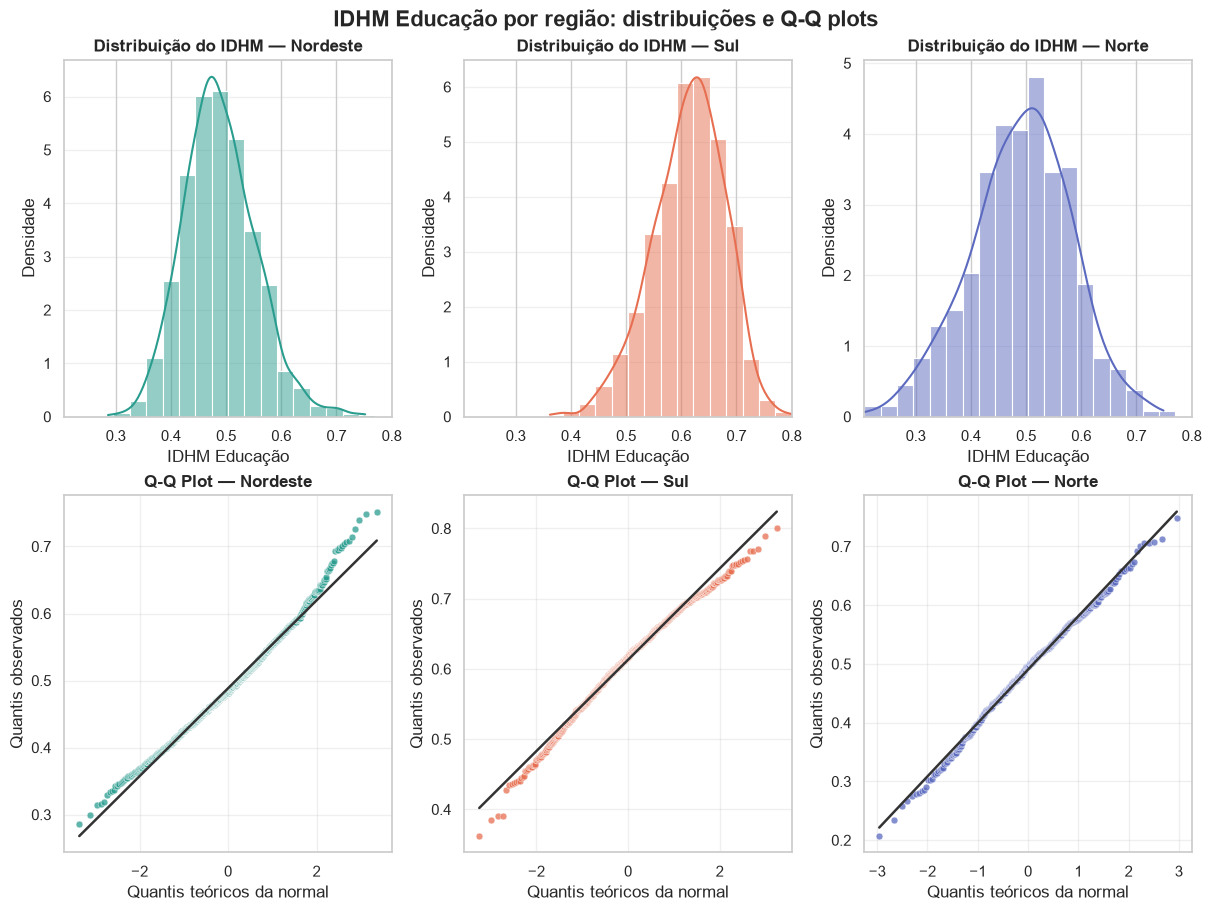

In [4]:
df = idh_data.copy()

colunas = {
    "Nordeste": "IDHM_Educacao Nordeste",
    "Sul": "IDHM_Educacao Sul",
    "Norte": "IDHM_Educacao Norte",
}

cores = {
    "Nordeste": "#2A9D8F",
    "Sul": "#E76F51",
    "Norte": "#5B6ABF",
}

dados = {
    regiao: df[coluna].dropna()
    for regiao, coluna in colunas.items()
}

# Intervalos comuns para os três histogramas
valores_gerais = pd.concat(dados.values(), ignore_index=True)
bins = np.linspace(valores_gerais.min(), valores_gerais.max(), 21)

# Tabela de assimetria e curtose
tabela = pd.DataFrame([
    {
        "Região": regiao,
        "Skewness (assimetria)": valores.skew(),
        "Kurtosis (curtose excedente)": valores.kurt(),
    }
    for regiao, valores in dados.items()
]).set_index("Região")

print("================== Análise de skewness e kurtosis ==================\n")
print(tabela.round(3).to_string())

# Duas linhas: histogramas acima e Q-Q plots abaixo
sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(2, 3, figsize=(12, 9), constrained_layout=True)

for coluna, (regiao, valores) in enumerate(dados.items()):
    cor = cores[regiao]

    # Histograma
    ax_hist = axes[0, coluna]
    sns.histplot(
        x=valores,
        bins=bins,
        stat="density",
        kde=True,
        color=cor,
        edgecolor="white",
        linewidth=0.8,
        ax=ax_hist,
    )
    ax_hist.set_title(f"Distribuição do IDHM — {regiao}", fontweight="bold")
    ax_hist.set_xlabel("IDHM Educação")
    ax_hist.set_ylabel("Densidade")
    ax_hist.set_xlim(valores_gerais.min(), valores_gerais.max())
    ax_hist.grid(axis="y", alpha=0.3)

    # Q-Q plot contra a distribuição normal
    ax_qq = axes[1, coluna]
    quantis_teoricos, quantis_observados = stats.probplot(
        valores,
        dist="norm",
        fit=False,
    )
    inclinacao, intercepto = np.polyfit(
        quantis_teoricos,
        quantis_observados,
        1,
    )

    ax_qq.scatter(
        quantis_teoricos,
        quantis_observados,
        color=cor,
        alpha=0.75,
        s=24,
        edgecolor="white",
        linewidth=0.4,
    )

    x_linha = np.array([min(quantis_teoricos), max(quantis_teoricos)])
    ax_qq.plot(
        x_linha,
        inclinacao * x_linha + intercepto,
        color="#333333",
        linewidth=1.8,
    )

    ax_qq.set_title(f"Q-Q Plot — {regiao}", fontweight="bold")
    ax_qq.set_xlabel("Quantis teóricos da normal")
    ax_qq.set_ylabel("Quantis observados")
    ax_qq.grid(alpha=0.3)

fig.suptitle(
    "IDHM Educação por região: distribuições e Q-Q plots",
    fontsize=16,
    fontweight="bold",
)
plt.show()

A análise visual dos histogramas indica que as distribuições do IDHM Educação nas regiões Nordeste, Sul e Norte apresentam formatos aproximadamente normais, embora sejam observadas pequenas diferenças em relação à simetria e ao comportamento das caudas.

A análise dos gráficos Q-Q também apresenta um alinhamento satisfatório dos quantis observados com os quantis teóricos da distribuição normal, especialmente nas regiões centrais. Entretanto, são identificados alguns desvios nas extremidades, principalmente nas distribuições do Nordeste e do Sul.

De modo geral, **não foram identificados desvios suficientemente acentuados que justifiquem descartar a utilização do teste t para comparação das médias**, desde que as demais condições necessárias à inferência sejam atendidas.

> O **Teorema Central do Limite** estabelece que, sob determinadas condições, a distribuição amostral da média tende a se aproximar de uma distribuição normal à medida que o tamanho da amostra aumenta, mesmo quando a distribuição original dos dados não é normal.
>
> Dessa forma, em amostras suficientemente grandes, desvios moderados da normalidade não necessariamente comprometem a validade de testes paramétricos de comparação de médias, como o teste t de Student. Entretanto, a qualidade dessa aproximação depende de características como assimetria, presença de valores extremos e independência das observações.

# 4. Construindo o Teste

### Teste t para comparar médias do IDHM entre Nordeste e Sul

**Hipóteses**
- H0: IDHM Nordeste = IDHM Sul
- H1: IDHM Nordeste < IDHM Sul (unilateral)

Para aplicar esse teste precisamos checar antes se as **variâncias** são iguais ou diferentes entre as amostras. Podemos confirmar isso utilizando o **Teste F** considerando:
- H0: var IDHM Nordeste = var IDHM Sul 
- H1: var IDHM Nordeste ≠ var IDHM Sul

In [5]:
regiao_1 = "Nordeste"
regiao_2 = "Sul"
alpha = 0.05

amostra_1 = dados[regiao_1].dropna()
amostra_2 = dados[regiao_2].dropna()

In [6]:
from scipy.stats import f

n_1 = len(amostra_1)
n_2 = len(amostra_2)

if n_1 < 2 or n_2 < 2:
    raise ValueError("Cada região precisa ter pelo menos duas observações.")

variancia_1 = amostra_1.var(ddof=1)
variancia_2 = amostra_2.var(ddof=1)

if variancia_1 <= 0 or variancia_2 <= 0:
    raise ValueError("O teste F exige variâncias amostrais maiores que zero.")

# Hipótese nula: as variâncias populacionais são iguais.
# Hipótese alternativa: as variâncias populacionais são diferentes.

estatistica_f = variancia_1 / variancia_2
gl_numerador = n_1 - 1
gl_denominador = n_2 - 1

# Valor-p bicaudal, mantendo a ordem definida para as regiões.
cauda_inferior = f.cdf(
    estatistica_f,
    gl_numerador,
    gl_denominador
)
cauda_superior = f.sf(
    estatistica_f,
    gl_numerador,
    gl_denominador
)
valor_p = 2 * min(cauda_inferior, cauda_superior)

print(f"Comparação: {regiao_1} x {regiao_2}")
print(f"Variância amostral de {regiao_1}: {variancia_1:.6f}")
print(f"Variância amostral de {regiao_2}: {variancia_2:.6f}")
print(f"Estatística F: {estatistica_f:.4f}")
print(f"Valor-p: {valor_p:.4f}")
print(f"Nível de significância (alpha): {alpha:.2f}")

if valor_p <= alpha:
    print(
        "\nConclusão: rejeitamos H0. "
        "Há evidência estatística de diferença entre as variâncias."
    )
else:
    print(
        "\nConclusão: não rejeitamos H0. "
        "Não há evidência estatística suficiente para concluir "
        "que as variâncias diferem."
    )

Comparação: Nordeste x Sul
Variância amostral de Nordeste: 0.004328
Variância amostral de Sul: 0.004249
Estatística F: 1.0186
Valor-p: 0.7303
Nível de significância (alpha): 0.05

Conclusão: não rejeitamos H0. Não há evidência estatística suficiente para concluir que as variâncias diferem.


In [7]:
from scipy.stats import ttest_ind

resultado_t = ttest_ind(
    amostra_1, # Nordeste
    amostra_2, # Sul
    equal_var=True,
    alternative="less"
)

diferenca_medias = amostra_1.mean() - amostra_2.mean()
graus_liberdade = len(amostra_1) + len(amostra_2) - 2

print(f"Comparação: {regiao_1} x {regiao_2}")
print(f"Média de {regiao_1}: {amostra_1.mean():.4f}")
print(f"Média de {regiao_2}: {amostra_2.mean():.4f}")
print(f"Diferença entre as médias ({regiao_1} - {regiao_2}): {diferenca_medias:.4f}")
print(f"Estatística t: {resultado_t.statistic:.4f}")
print(f"Graus de liberdade: {graus_liberdade}")
print(f"Valor-p: {resultado_t.pvalue:.6f}")

if resultado_t.pvalue <= alpha:
    print(
        "\nConclusão: rejeitamos H0. "
        "Há evidência estatística de que a média do IDHM do Nordeste "
        "é menor que a do Sul."
    )
else:
    print(
        "\nConclusão: não rejeitamos H0. "
        "Não há evidência estatística suficiente para afirmar que "
        "a média do IDHM do Nordeste é menor que a do Sul."
    )

Comparação: Nordeste x Sul
Média de Nordeste: 0.4884
Média de Sul: 0.6130
Diferença entre as médias (Nordeste - Sul): -0.1246
Estatística t: -50.8222
Graus de liberdade: 2981
Valor-p: 0.000000

Conclusão: rejeitamos H0. Há evidência estatística de que a média do IDHM do Nordeste é menor que a do Sul.


### Teste t para comparar médias do IDHM entre Nordeste e Norte

**Hipóteses**
- H0: IDHM Nordeste = IDHM Norte
- H1: IDHM Nordeste ≠ IDHM Norte (bicaudal)

Para aplicar esse teste precisamos checar antes se as **variâncias** são iguais ou diferentes entre as amostras. Podemos confirmar isso utilizando o **Teste F** considerando:
- H0: var IDHM Nordeste = var IDHM Norte 
- H1: var IDHM Nordeste ≠ var IDHM Norte

In [8]:
regiao_1 = "Norte"
regiao_2 = "Nordeste"
alpha = 0.05

amostra_1 = dados[regiao_1].dropna()
amostra_2 = dados[regiao_2].dropna()

In [9]:
n_1 = len(amostra_1)
n_2 = len(amostra_2)

if n_1 < 2 or n_2 < 2:
    raise ValueError("Cada região precisa ter pelo menos duas observações.")

variancia_1 = amostra_1.var(ddof=1)
variancia_2 = amostra_2.var(ddof=1)

if variancia_1 <= 0 or variancia_2 <= 0:
    raise ValueError("O teste F exige variâncias amostrais maiores que zero.")

# Hipótese nula: as variâncias populacionais são iguais.
# Hipótese alternativa: as variâncias populacionais são diferentes.

estatistica_f = variancia_1 / variancia_2
gl_numerador = n_1 - 1
gl_denominador = n_2 - 1

# Valor-p bicaudal, mantendo a ordem definida para as regiões.
cauda_inferior = f.cdf(
    estatistica_f,
    gl_numerador,
    gl_denominador
)
cauda_superior = f.sf(
    estatistica_f,
    gl_numerador,
    gl_denominador
)
valor_p = 2 * min(cauda_inferior, cauda_superior)

print(f"Comparação: {regiao_1} x {regiao_2}")
print(f"Variância amostral de {regiao_1}: {variancia_1:.6f}")
print(f"Variância amostral de {regiao_2}: {variancia_2:.6f}")
print(f"Estatística F: {estatistica_f:.4f}")
print(f"Valor-p: {valor_p:.4f}")
print(f"Nível de significância (alpha): {alpha:.2f}")

if valor_p <= alpha:
    print(
        "\nConclusão: rejeitamos H0. "
        "Há evidência estatística de diferença entre as variâncias."
    )
else:
    print(
        "\nConclusão: não rejeitamos H0. "
        "Não há evidência estatística suficiente para concluir "
        "que as variâncias diferem."
    )

Comparação: Norte x Nordeste
Variância amostral de Norte: 0.008220
Variância amostral de Nordeste: 0.004328
Estatística F: 1.8994
Valor-p: 0.0000
Nível de significância (alpha): 0.05

Conclusão: rejeitamos H0. Há evidência estatística de diferença entre as variâncias.


In [10]:
resultado_t = ttest_ind(
    amostra_1, # Norte
    amostra_2, # Nordeste
    equal_var=False,
    alternative="two-sided"
)

diferenca_medias = amostra_1.mean() - amostra_2.mean()
graus_liberdade = resultado_t.df

print(f"Comparação: {regiao_1} x {regiao_2}")
print(f"Média de {regiao_1}: {amostra_1.mean():.4f}")
print(f"Média de {regiao_2}: {amostra_2.mean():.4f}")
print(f"Diferença entre as médias ({regiao_1} - {regiao_2}): {diferenca_medias:.4f}")
print(f"Estatística t: {resultado_t.statistic:.4f}")
print(f"Graus de liberdade: {graus_liberdade}")
print(f"Valor-p: {resultado_t.pvalue:.6g}")

if resultado_t.pvalue <= alpha:
    print(
        "\nConclusão: rejeitamos H0. "
        "Há evidência estatística de diferença entre as médias."
    )
else:
    print(
        "\nConclusão: não rejeitamos H0. "
        "Não há evidência estatística suficiente para concluir "
        "que as médias diferem."
    )

Comparação: Norte x Nordeste
Média de Norte: 0.4904
Média de Nordeste: 0.4884
Diferença entre as médias (Norte - Nordeste): 0.0020
Estatística t: 0.4412
Graus de liberdade: 571.3621873883434
Valor-p: 0.659212

Conclusão: não rejeitamos H0. Não há evidência estatística suficiente para concluir que as médias diferem.


# 5. Considerações Finais

Os objetivos propostos para este estudo foram alcançados, permitindo compreender e aplicar os fundamentos dos **testes de hipóteses**. Ao longo do notebook, foram abordadas as etapas fundamentais do procedimento inferencial, desde a formulação das hipóteses nula e alternativa até o cálculo das estatísticas de teste, a definição do nível de significância, a avaliação dos pressupostos e a interpretação dos resultados por meio do p-valor. A aplicação prática desses conceitos possibilitou consolidar o entendimento sobre o processo de tomada de decisão estatística, utilizando como contexto a comparação dos indicadores de IDHM Educação entre diferentes regiões brasileiras.

Como ressalva metodológica, destaca-se uma limitação da **abordagem tradicional de seleção entre os testes t de Student e t de Welch**, baseada na aplicação prévia de um teste F para verificar a homogeneidade das variâncias. Embora essa estratégia seja frequentemente apresentada no ensino de inferência estatística, **o teste F é sensível a desvios da normalidade**, e a utilização de seu resultado como critério de seleção pode comprometer as propriedades inferenciais do procedimento. Além disso, a não rejeição da hipótese de igualdade das variâncias não constitui evidência suficiente para afirmar que elas sejam iguais. Nesse contexto, o **teste t de Welch representa uma alternativa metodologicamente mais robusta**, pois não pressupõe igualdade das variâncias populacionais e **geralmente apresenta desempenho semelhante ao teste t clássico** quando essa condição é satisfeita. Portanto, embora a abordagem tradicional tenha sido utilizada neste estudo com finalidade didática, é importante reconhecer suas limitações e considerar procedimentos mais robustos em aplicações práticas.